In [131]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
import seaborn as sns

pd.set_option('display.max_columns', 50) # tells pandas to display up to 50 columns when printing a DataFrame
pd.set_option('display.max_rows', 50)    # tells pandas to display up to 50 rows when printing a DataFrame

Graph_Color = ['#1A9D48', '#0a0b0b']
Edgecolor = ['#000000', '#898787']
Heatmap = ['Greens']


# Importing and Data Exploration

In [132]:
Directory = '/Users/josemenezes/Faculdade/Projetos/Projeto ML/Projeto-Machine-Learning/project/data/'

train_data = pd.read_csv(Directory + 'train.csv', index_col='ID', parse_dates=['purchase_date'])
teste_data = pd.read_csv(Directory + 'test.csv', index_col='ID', parse_dates=['purchase_date'])
clients = pd.read_csv(Directory + 'clientes.csv', index_col='customer_id')
sample_submission= pd.read_csv(Directory+ 'sample_submission.csv')

target = 'repeat_purchase_90d'

print('train data:', train_data.shape, '| test data:', teste_data.shape, '| clients data:', clients.shape)

train data: (6534, 38) | test data: (986, 37) | clients data: (1143, 12)


In [133]:
train_data.columns

Index(['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_',
       'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo',
       'N_ Detalhes', 'invoice_count_current_purchase', 'repeat_purchase_90d',
       'days_since_previous_purchase', 'customer_tenure_days',
       'prior_purchase_count', 'prior_total_spend',
       'prior_mean_purchase_value', 'prior_std_purchase_value',
       'prior_min_purchase_value', 'prior_max_purchase_value',
       'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d',
       'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d',
       'spend_180d', 'purchase_count_365d', 'spend_365d', 'customer_id',
       'payment_type', 'salesperson', 'commercial_zone', 'transport_method',
       'warehouse', 'document_series', 'purchase_date', 'random_noise'],
      dtype='str')

In [134]:
train_data.head().T

ID,10000000,10000001,10000002,10000003,10000004
Total a Pagar,558.11,978.8,10.33,856.83,1616.1
Total Bruto,510.9,830.02,12.0,696.61,1488.85
Total Liquido,453.75,795.77,8.4,696.61,1313.9
Total Imp_,104.36,183.03,1.93,160.22,302.2
Total Portes,0.0,0.0,0.0,0.0,0.0
Total Desc_ Global,0.0,0.0,0.0,0.0,0.0
Total Desc_ Linha,57.15,34.25,3.6,0.0,174.95
Custo,153.099911,472.943134,6.097485,408.167275,485.401864
N_ Detalhes,4.0,32.0,1.0,9.0,33.0
invoice_count_current_purchase,1.0,1.0,1.0,1.0,1.0


In [135]:
train_data.tail().T

ID,10007670,10007671,10007672,10007673,10007674
Total a Pagar,3023.34,1362.26,4396.55,452.07,951.71
Total Bruto,3761.38,1723.1,3574.43,483.6,982.0
Total Liquido,2458.0,1107.53,3574.43,367.54,773.75
Total Imp_,565.34,254.73,822.12,84.53,177.96
Total Portes,0.0,0.0,0.0,0.0,0.0
Total Desc_ Global,0.0,34.25,0.0,0.0,0.0
Total Desc_ Linha,1303.38,581.32,0.0,116.06,208.25
Custo,1099.19,197.514,2075.838024,265.159468,224.543079
N_ Detalhes,49.0,16.0,78.0,7.0,30.0
invoice_count_current_purchase,1.0,1.0,1.0,1.0,1.0


In [136]:
train_data.shape

(6534, 38)

In [137]:
train_data.info()

<class 'pandas.DataFrame'>
Index: 6534 entries, 10000000 to 10007674
Data columns (total 38 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   Total a Pagar                   6469 non-null   float64       
 1   Total Bruto                     6469 non-null   float64       
 2   Total Liquido                   6469 non-null   float64       
 3   Total Imp_                      6469 non-null   float64       
 4   Total Portes                    6469 non-null   float64       
 5   Total Desc_ Global              6469 non-null   float64       
 6   Total Desc_ Linha               6469 non-null   float64       
 7   Custo                           6469 non-null   float64       
 8   N_ Detalhes                     6469 non-null   float64       
 9   invoice_count_current_purchase  6469 non-null   float64       
 10  repeat_purchase_90d             6534 non-null   int64         
 11  days_sinc

- On first inspection there are a few features with wrong dtypes
- A lot of statistics features have many missing values 

In [138]:
train_data.describe().round(2).T

,count,mean,min,25%,50%,75%,max,std
Total a Pagar,6469.0,925.56,0.93,188.92,476.74,1087.67,22297.21,1335.0
Total Bruto,6469.0,886.15,0.83,175.74,445.74,1036.7,21578.28,1327.64
Total Liquido,6469.0,773.34,0.76,154.38,389.91,903.37,18127.81,1136.36
Total Imp_,6469.0,152.22,0.0,29.93,79.74,184.84,4169.4,225.26
Total Portes,6469.0,1.15,0.0,0.0,0.0,0.0,181.06,5.84
Total Desc_ Global,6469.0,0.35,0.0,0.0,0.0,0.0,218.49,5.12
Total Desc_ Linha,6469.0,112.47,0.0,0.0,13.13,92.28,4103.44,289.99
Custo,6469.0,328.17,0.0,49.05,152.54,396.06,7427.4,519.51
N_ Detalhes,6469.0,21.52,1.0,4.0,11.0,29.0,423.0,27.71
invoice_count_current_purchase,6469.0,1.07,1.0,1.0,1.0,1.0,5.0,0.31


- We can see many features have small mean and a very big max value which suggests outlier behaviour or in the case of prior_mean_purchase_value could be incorrect values.
- we can also see many impossible negative values.
- total_postage seems to have very few and high values, wich seems ok because many users probably don't order from distance, but may reveal this feature as less significant.

## String columns

In [139]:
train_data.describe(include='str').T

,count,unique,top,freq
payment_type,6274,9,Maybe Tomorrow Payment 7,4565
salesperson,6275,9,VLOOKUP Master 1,4054
commercial_zone,6469,5,Decorative Dashboard Zone 4,6260
transport_method,6273,80,Maybe Tomorrow Delivery 72,1119
warehouse,6274,2,Final Excel Warehouse 1,6253
document_series,6469,3,Ctrl Z Series 2,2738


In [140]:
str_columns =['payment_type', 'salesperson', 'commercial_zone', 'transport_method',
             'warehouse', 'document_series']
str_df = []
for c in str_columns:
    str_df.append({'variable': c, 'levels_train': train_data[c].nunique(),
                 'top_level_share_train': round(train_data[c].value_counts(normalize=True).iloc[0], 2),
    })
pd.DataFrame(str_df)

,variable,levels_train,top_level_share_train
0,payment_type,9,0.73
1,salesperson,9,0.65
2,commercial_zone,5,0.97
3,transport_method,80,0.18
4,warehouse,2,1.00
5,document_series,3,0.42


In [141]:
for col in str_columns:
    print(f'{col} ({train_data[col].nunique()} unique values)')
    print((train_data[col].value_counts(dropna=False, normalize=True) * 100).round(2).to_string())
    print()

payment_type (9 unique values)
payment_type
Maybe Tomorrow Payment 7     69.87
Maybe Tomorrow Payment 12    15.17
Maybe Tomorrow Payment 9      7.68
NaN                           3.98
Maybe Tomorrow Payment 10     2.05
Maybe Tomorrow Payment 8      0.61
Maybe Tomorrow Payment 2      0.32
Maybe Tomorrow Payment 4      0.14
Maybe Tomorrow Payment 11     0.12
Maybe Tomorrow Payment 3      0.06

salesperson (9 unique values)
salesperson
VLOOKUP Master 1    62.04
VLOOKUP Master 4    22.36
VLOOKUP Master 9     5.88
NaN                  3.96
VLOOKUP Master 7     3.08
VLOOKUP Master 2     1.88
VLOOKUP Master 3     0.46
VLOOKUP Master 6     0.18
VLOOKUP Master 5     0.11
VLOOKUP Master 8     0.05

commercial_zone (5 unique values)
commercial_zone
Decorative Dashboard Zone 4    95.81
Decorative Dashboard Zone 2     2.31
NaN                             0.99
Decorative Dashboard Zone 3     0.86
Decorative Dashboard Zone 6     0.02
Decorative Dashboard Zone 7     0.02

transport_method (80 unique v

# Duplicates

In [143]:
duplicates = train_data.duplicated().sum()
print(f'Number of duplicate rows in the training data: {duplicates}')

per_customer = train_data.groupby('customer_id').size().sort_values(ascending=False)
print(per_customer.head(10))
print()
print(per_customer.describe().round(2))


Number of duplicate rows in the training data: 10
customer_id
103940    277
258332    203
755628    112
151492     89
519184     89
239651     81
703834     80
227020     74
497930     73
488020     67
dtype: int64

count    610.00
mean      10.71
std       19.97
min        1.00
25%        1.00
50%        4.00
75%       12.00
max      277.00
dtype: float64


# Missing Values

In [144]:
NA_train = train_data.isna().sum()
NA_Dataframe = pd.DataFrame({'Total NA' : NA_train, 'Total NA %': (100*(NA_train/len(train_data))).round(2)})
NA_Dataframe[NA_Dataframe['Total NA']>0].sort_values('Total NA', ascending=False)


,Total NA,Total NA %
prior_std_gap_days,1478,22.62
prior_mean_gap_days,1308,20.02
prior_std_purchase_value,1113,17.03
prior_mean_purchase_value,862,13.19
days_since_previous_purchase,861,13.18
prior_min_purchase_value,668,10.22
prior_max_purchase_value,668,10.22
transport_method,261,3.99
payment_type,260,3.98
spend_365d,260,3.98


- a lot of features have 65 values missing, perhaps they are all in the same row when comparing to info() analysis where most feature have 65 missing values. Potential to eliminate.
- statistic features like 'prior_std_gap_days' with a lot of missing values. 

# Univariate Analysis

In [ ]:
def plot_categorical_distribution(data, feature):
   
    original_value_counts = data[feature].value_counts()
    mode_value = original_value_counts.idxmax()
    mode_frequency = original_value_counts.max()
    missing_count = data[feature].isnull().sum()
    total_count = len(data)

    data_copy = data.copy()

    if len(original_value_counts) > 15:
        top_categories = original_value_counts.index[:15]

        data_copy[feature] = data_copy[feature].apply(lambda x: x if x in top_categories else 'Other')

        sorted_feature = data_copy[feature].value_counts().index
    else:
        sorted_feature = original_value_counts.index

    data_copy[feature] = pd.Categorical(data_copy[feature], categories=sorted_feature, ordered=True)

    plt.figure(figsize=(10, 6))
    plt.title(f'Distribution of {feature}', fontsize=16)

    blue_palette = ["#ADD8E6", "#87CEEB", "#6495ED", "#1E90FF", "#4169E1"]

    ax = sns.countplot(data=data_copy, x=feature, hue=feature, palette=blue_palette, edgecolor="black", order=sorted_feature, legend=False)
    plt.xlabel(feature, fontsize=12)
    plt.ylabel("Count", fontsize=12)
    plt.xticks(rotation=90)

    total = len(data_copy[feature].dropna())
    for p in ax.patches:
        count = p.get_height()
        percentage = f'{100 * count / total:.1f}%'
        ax.annotate(percentage,
                    (p.get_x() + p.get_width() / 2., count),
                    ha = 'center', va = 'bottom',
                    fontsize=10,
                    color='black',
                    xytext=(0, 5),
                    textcoords='offset points')

    plt.show()

    stats = pd.DataFrame({
        "Count": [total_count - missing_count],
        "Unique": [original_value_counts.nunique()],
        "Top (Mode)": [mode_value],
        "Frequency of Top": [mode_frequency],
        "Missing": [missing_count],
        "Missing %": [(missing_count / total_count) * 100],
    })

    display(stats)

### Target evaluation

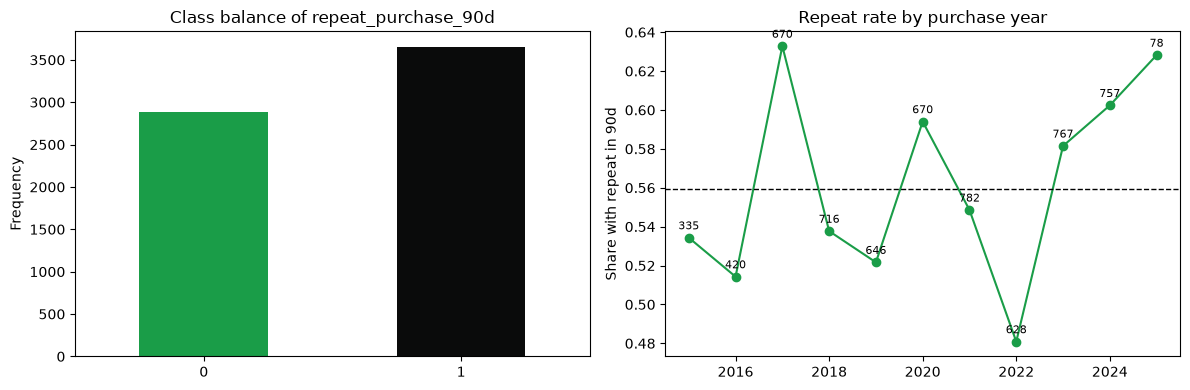

repeat_purchase_90d
1    0.56
0    0.44
Name: proportion, dtype: float64


In [145]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

train_data[target].value_counts().sort_index().plot.bar(ax=ax[0], color=[Graph_Color[0], Graph_Color[1]])
ax[0].set_title('Class balance of repeat_purchase_90d')
ax[0].set_xlabel(''); ax[0].set_ylabel('Frequency'); ax[0].tick_params(axis='x', rotation=0)

yearly = train_data.groupby(train_data['purchase_date'].dt.year)[target].agg(['mean', 'size'])
ax[1].plot(yearly.index, yearly['mean'], marker='o', color=Graph_Color[0])
ax[1].axhline(train_data[target].mean(), ls='--', color=Edgecolor[0], lw=1)
ax[1].set_title('Repeat rate by purchase year')   
ax[1].set_ylabel('Share with repeat in 90d')
for yr, r in yearly.iterrows():
    ax[1].annotate(int(r['size']), (yr, r['mean']), textcoords='offset points', xytext=(0, 6),
                   ha='center', fontsize=8)
plt.tight_layout(); 
plt.show()

print(train_data[target].value_counts(normalize=True).round(2))

### Transaction features and correlations

In [146]:
transaction_features = ['total_due', 'total_gross', 'total_net', 'total_taxes', 'total_postage',
                        'total_global_discount', 'total_line_discount', 'cost',
                        'number_of_items', 'invoice_count_current_purchase']
summary = train_data[transaction_features].describe().T
print(summary.round(2).to_string())

                                 count    mean      std   min     25%     50%      75%       max
total_due                       6469.0  925.56  1335.00  0.93  188.92  476.74  1087.67  22297.21
total_gross                     6469.0  886.15  1327.64  0.83  175.74  445.74  1036.70  21578.28
total_net                       6469.0  773.34  1136.36  0.76  154.38  389.91   903.37  18127.81
total_taxes                     6469.0  152.22   225.26  0.00   29.93   79.74   184.84   4169.40
total_postage                   6469.0    1.15     5.84  0.00    0.00    0.00     0.00    181.06
total_global_discount           6469.0    0.35     5.12  0.00    0.00    0.00     0.00    218.49
total_line_discount             6469.0  112.47   289.99  0.00    0.00   13.13    92.28   4103.44
cost                            6469.0  328.17   519.51  0.00   49.05  152.54   396.06   7427.40
number_of_items                 6469.0   21.52    27.71  1.00    4.00   11.00    29.00    423.00
invoice_count_current_purchase

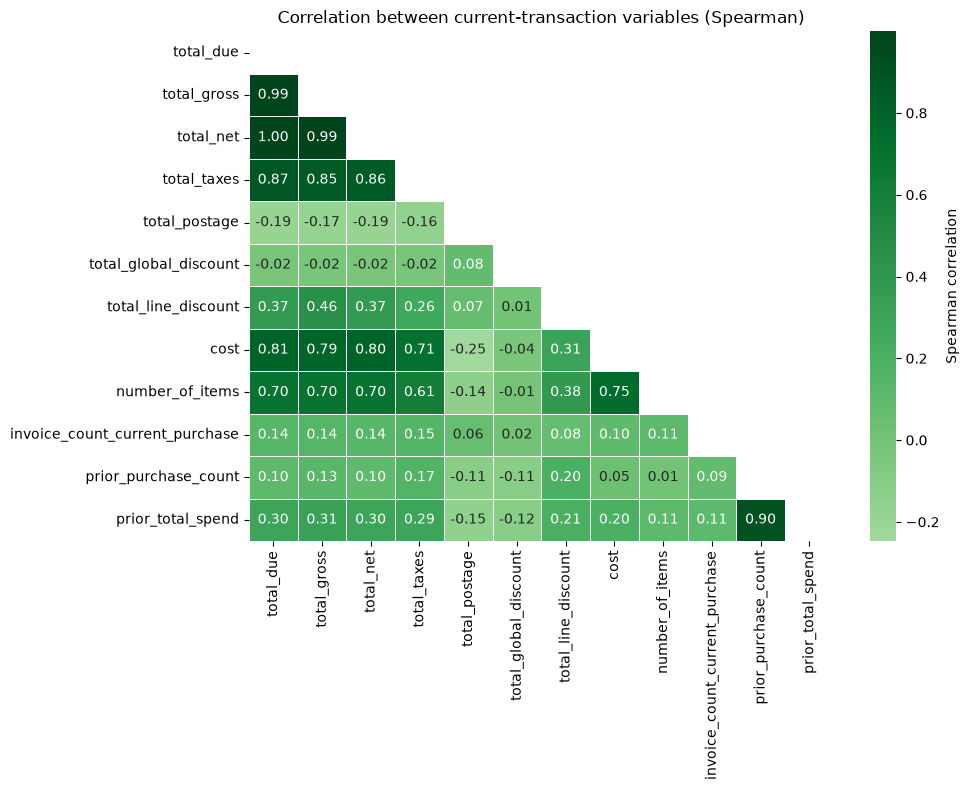

In [147]:
transaction_features = [
    'total_due', 'total_gross', 'total_net', 'total_taxes', 'total_postage',
       'total_global_discount', 'total_line_discount', 'cost',
       'number_of_items', 'invoice_count_current_purchase', 'prior_purchase_count', 'prior_total_spend'
]
corr = train_data[transaction_features].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))   # hide the duplicate upper half

plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap=Heatmap[0], center=0, linewidths=0.5, cbar_kws={'label': 'Spearman correlation'})
plt.title('Correlation between current-transaction variables (Spearman)')
plt.tight_layout()
plt.show()

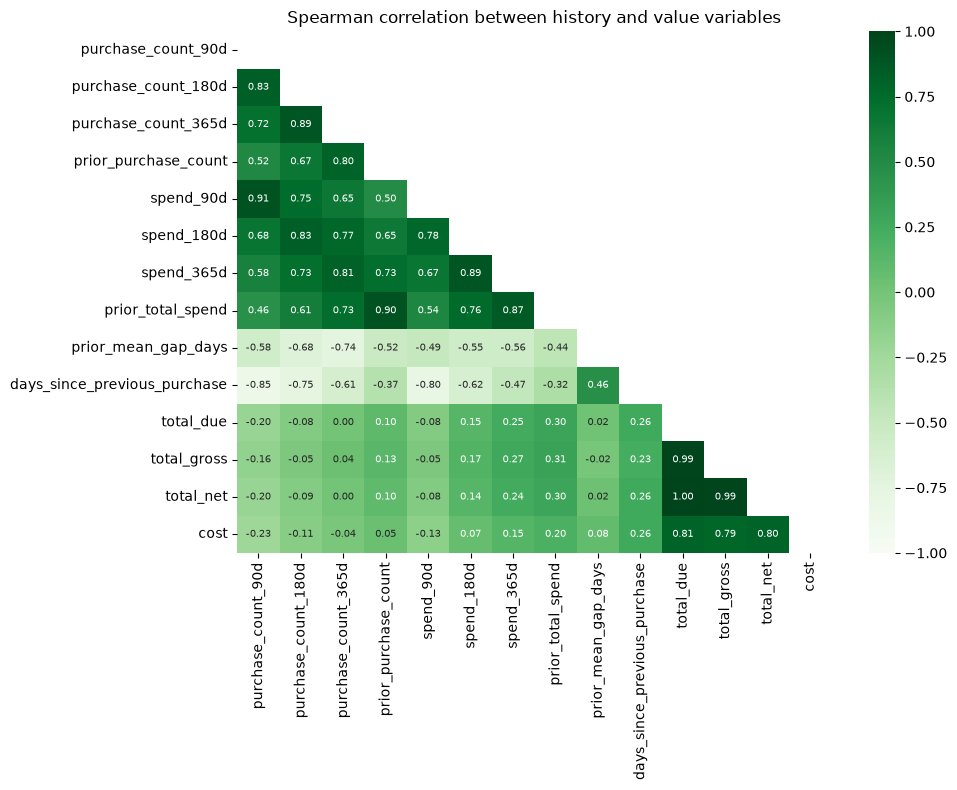

In [148]:
freq_value = ['purchase_count_90d', 'purchase_count_180d', 'purchase_count_365d', 'prior_purchase_count',
              'spend_90d', 'spend_180d', 'spend_365d', 'prior_total_spend', 'prior_mean_gap_days',
              'days_since_previous_purchase', 'total_due', 'total_gross', 'total_net', 'cost']
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(train_data[freq_value].corr(method='spearman'), dtype=bool)) 
sns.heatmap(train_data[freq_value].corr(method='spearman'), mask=mask, cmap=Heatmap[0], center=0,
            vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Spearman correlation between history and value variables')
plt.tight_layout(); plt.show()